# ENCS5341 - Assignment 2
## Data Integration, Cleaning, EDA and Insight Discovery

**Students:** Omar Adas (1230703) & Jibreel Bornat (1230872)

In this notebook we work on the second-hand marketplace data that all the class collected in Assignment 1.
Jibreel did the integration and cleaning with python scripts (they are in our repo, phase0 to phase3), and the output was two CSV files:

* `marketplace_raw.csv` : all submissions merged together, without changing any value
* `marketplace_cleaned.csv` : the data after cleaning

In the notebook we first check this two files, then we do the EDA and write the insights.

Note: student IDs and image paths was removed from the files we submit, every row have a new id like `item-0001`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os

sns.set_style("whitegrid")
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Liberation Serif"]
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

os.makedirs("figures", exist_ok=True)   # we save the figures here to use them in the report

# read the raw file as text so nothing change
raw = pd.read_csv("marketplace_raw.csv", dtype=str, keep_default_na=False)
clean = pd.read_csv("marketplace_cleaned.csv")
print("raw shape  :", raw.shape)
print("clean shape:", clean.shape)

raw shape  : (1801, 11)
clean shape: (1751, 16)


## 1. Data Integration

What was done in the integration step (Jibreel's phase 0 and phase 1 scripts):
* The class export had 129 files from 128 submissions. If a student submitted more than one time we took the last one, so we have **120 students**.
* The files was 86 CSV, 33 Excel and 1 file with `;` as delimiter. We read all of them as text so nothing change (like "Unknown" or leading zeros).
* Every student used different column names (`Item ID`, `item_id`, `ID` ...), so we mapped all of them to one schema: title, description, category, age_raw, condition_raw, price_raw, currency_raw.
* The item IDs was repeated between students (52 IDs like `item_001` used by many students), so we made a new unique ID for each row.
* Images: 1803 photo files. 1507 rows linked by exact file name, 293 by file name pattern, 1 row without photo.

Lets check this on the raw file:

In [2]:
print("number of rows:", len(raw))
print("record ids unique?", raw["public_record_id"].is_unique)
print("120 students: 119 x 15 + 1 x 16 =", 119 * 15 + 16)
print("different category labels:", raw.loc[raw["category"].str.strip() != "", "category"].nunique())
print()
print(raw["image_status"].value_counts())

number of rows: 1801
record ids unique? True
120 students: 119 x 15 + 1 x 16 = 1801
different category labels: 132

image_status
confirmed    1507
plausible     293
missing         1
Name: count, dtype: int64


## 2. Data Quality Assessment

### 2.1 Missing values
The raw file is text, so `isna()` is not enough. A value is missing if it is empty, only spaces, or a word like "Unknown".

In [3]:
missing_words = ["", "unknown", "unkown", "n/a", "na", "none", "-"]

cols = ["title", "description", "category", "age_raw", "condition_raw", "price_raw", "currency_raw"]
for col in cols:
    n = raw[col].str.strip().str.lower().isin(missing_words).sum()
    print(col, ":", n, "missing,", round(n / len(raw) * 100, 2), "%")

n = (raw["image_status"] == "missing").sum()
print("image :", n, "missing,", round(n / len(raw) * 100, 2), "%")

# how many rows have at least one missing value
row_missing = pd.Series(False, index=raw.index)     # start with all False
for col in cols:
    row_missing = row_missing | raw[col].str.strip().str.lower().isin(missing_words)
print("\nrows with at least one missing value:", row_missing.sum(), "=", round(row_missing.sum() / len(raw) * 100, 2), "%")

title : 0 missing, 0.0 %
description : 3 missing, 0.17 %
category : 1 missing, 0.06 %
age_raw : 385 missing, 21.38 %
condition_raw : 20 missing, 1.11 %
price_raw : 33 missing, 1.83 %
currency_raw : 35 missing, 1.94 %
image : 1 missing, 0.06 %

rows with at least one missing value: 431 = 23.93 %


Age is the worst column, around 21% is missing. Other columns are only 1-2% or less.
We noticed that the missing ages comes mostly from few students (3 students didnt write any age).

### 2.2 Duplicates

In [4]:
print("rows exactly the same (7 columns):", raw.duplicated(subset=cols).sum())

title = raw["title"].str.lower().str.strip()
same_title = title[title.duplicated(keep=False)]
print("rows that share the same title:", len(same_title), "in", same_title.nunique(), "groups")
print(raw.loc[same_title.index, ["public_record_id", "title", "price_raw", "currency_raw"]].sort_values("title").head(8))

rows exactly the same (7 columns): 0
rows that share the same title: 42 in 20 groups
     public_record_id                       title price_raw currency_raw
205         item-0206                  Sunglasses        75            ₪
1662        item-1663                Coffee Maker       170          ILS
390         item-0391                Coffee Maker        50          USD
1225        item-1226                 Cooking pot                       
1526        item-1527                 Cooking pot        40          ILS
931         item-0932   Excellent Sport Treadmill       900          ILS
443         item-0444   Excellent Sport Treadmill       900          ILS
61          item-0062  Fossil Q Wander Smartwatch       300          ILS


There is no exact duplicate rows because each student wrote his own text. Same title is not enough (two students can both have a used iPhone 11).
So in the cleaning step the duplicates was checked by comparing the photos (same or almost same photo) and the listing details (title, price, link).
The result was **41 groups with 91 rows**, we kept one row from each group and removed **50 copies**. Most of them was the same online ad collected by two students.

### 2.3 Inconsistencies

In [5]:
print("Some category labels:")
print(raw[raw["category"].str.lower().str.contains("clothing")]["category"].value_counts().head(5))
print(raw[raw["category"].str.lower().str.contains("sports")]["category"].value_counts().head(5))

print("Currency as students wrote it:")
print(raw["currency_raw"].str.strip().value_counts())

Some category labels:
category
Clothing and accessories     169
Clothing and Accessories      38
Clothing & Accessories        25
Clothing                       9
Clothing and accessories       5
Name: count, dtype: int64
category
Sports equipment     82
Sports Equipment     43
sports equipments     3
Sports                2
Sports Equipment      2
Name: count, dtype: int64
Currency as students wrote it:
currency_raw
ILS        1113
USD         390
GBP          54
NIS          48
             23
EUR          23
ils          21
CHF          19
₪            15
Shekel       15
Unknown      12
dollar       10
JOD          10
usd           9
AED           9
SGD           7
shekel        6
EGP           6
SAR           4
TWD           2
LYD           1
IQD           1
SEK           1
AUD           1
INR           1
Name: count, dtype: int64


In [6]:
# show values that pandas can not convert to number
for col in ["age_raw", "condition_raw", "price_raw"]:
    numbers = pd.to_numeric(raw[col], errors="coerce")
    bad = raw[col][numbers.isna() & (raw[col].str.strip() != "")]
    print(col, ":", bad.unique()[:12])

age_raw : <StringArray>
['Unknown', '1 month', '3 years', '3 moths', '2 years', '4 years', '4 years ', '2 months', '6 months', '2  years', '10 months', '1 year']
Length: 12, dtype: str
condition_raw : <StringArray>
['Unknown', 'good', 'poor', 'Fair', 'Like new', 'Fair ', '4 — Good', '2 — Poor', '4 — Good ', '5 — Like New']
Length: 10, dtype: str
price_raw : <StringArray>
['1,589.00', '350,000', '270,000', '93,000', '245,000', '70,000', '1,000.', '180,000.', '1,400.', '1,200', '2,000', '15,000.00']
Length: 12, dtype: str


The problems we found:
* **Category:** 132 labels for around 12 real groups (`Sports equipment` / `Sports Equipment`, `Clothing` / `Clothing & Accessories` ...)
* **Currency:** shekel written as ILS, NIS, ils, ₪, Shekel. Also the word "dollar" and 16 currencies in total.
* **Age:** text like `2 years`, `6 months`, `3 moths` and `2.` from Excel.
* **Condition:** words instead of numbers like `good`, `Fair`, `4 — Good`.
* **Price:** comma inside big numbers and `500.`

### 2.4 Invalid values and outliers
To check this we convert the text to numbers in a simple way first.

In [7]:
def to_number(x):
    x = str(x).strip().lower().replace(",", "").rstrip(".")
    try:
        return float(x)
    except ValueError:
        return np.nan

def age_to_number(x):
    x = str(x).strip().lower()
    n = to_number(x.split(" ")[0])
    if "month" in x or "moth" in x:
        n = n / 12
    return n

words = {"like new": 5, "good": 4, "fair": 3, "poor": 2, "very poor": 1}
def cond_to_number(x):
    x = str(x).strip().lower()
    if x[:1].isdigit():
        return float(x.split(" ")[0])
    return words.get(x, np.nan)

price_num = raw["price_raw"].map(to_number)
age_num = raw["age_raw"].map(age_to_number)
cond_num = raw["condition_raw"].map(cond_to_number)

print("negative prices:", (price_num < 0).sum(), "| zero prices:", (price_num == 0).sum())
print("negative ages:", (age_num < 0).sum())
print("condition not in 1-5:")
print(raw.loc[(cond_num < 1) | (cond_num > 5), ["public_record_id", "title", "condition_raw"]])

negative prices: 0 | zero prices: 1
negative ages: 0
condition not in 1-5:
     public_record_id                title condition_raw
1163        item-1164  Used play station 5             9


In [8]:
# IQR rule from the lecture: outlier if value > Q3 + 1.5*IQR (or < Q1 - 1.5*IQR)
shekel = raw["currency_raw"].str.strip().str.lower().isin(["ils", "nis", "₪", "shekel"])
x = price_num[shekel].dropna()      # only shekel prices, so we compare same currency
q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1
print("price: Q1 =", q1, " Q3 =", q3, " IQR =", iqr, " upper fence =", q3 + 1.5 * iqr)
print("price outliers:", (x > q3 + 1.5 * iqr).sum())

x = age_num.dropna()
q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3 - q1
print("age: Q1 =", q1, " Q3 =", q3, " IQR =", iqr, " upper fence =", q3 + 1.5 * iqr)
print("age outliers:", (x > q3 + 1.5 * iqr).sum())

price: Q1 = 30.0  Q3 = 599.5  IQR = 569.5  upper fence = 1453.75
price outliers: 158
age: Q1 = 1.0  Q3 = 7.0  IQR = 6.0  upper fence = 16.0
age outliers: 160


Only one value is really invalid: condition = 9 (a PlayStation 5). No negative prices or ages, and the 0 price is a free give-away.

The IQR rule give many high prices and ages, but in a marketplace this is normal, a car and a pencil case are in the same column.
We checked the extreme ones and they are real (a chicken farm for 800000 ILS, cars, a 1954 Fender guitar, antiques 216 years old), so we **kept them** and didnt delete.

## 3. Data Cleaning

The cleaning was done by the phase 3 script, every change saved in a log. Summary:

| Problem | What we did |
|---|---|
| Category labels | fix case, `&`/`and`, plural → 98 labels in 12 groups |
| Currency | NIS, ₪, Shekel → ILS. 541 foreign prices converted to ILS with one fixed exchange rate (24 Nov 2026) |
| Text in numbers | remove commas and dots, months → years, condition words → numbers |
| Condition = 9 | changed to 5 because description says "like new" |
| Duplicates | 50 copies removed |
| Wrong photos | 14 replaced, 5 removed |
| Missing age | first from the text (model year, "bought in 2019"...), then **median** of the category |
| Missing condition | **mode** (4) |
| Missing price | **median** of similar items from other students, else category median |
| Outliers | kept, only flagged |

Why median and mode? From the lecture: for skewed data we use the median not the mean, and price and age are very skewed (see section 4). Condition is a rating (ordinal), so the mode make more sense.

Now we check the cleaned file:

In [9]:
print("shape:", clean.shape, "| unique ids:", clean["public_record_id"].is_unique)
print("rows removed:", len(raw) - len(clean))
print("\nmissing values:")
print(clean[["category_group", "age_years", "condition_rating", "price_ils"]].isna().sum())
print("\ncondition between 1 and 5:", clean["condition_rating"].between(1, 5).all())
print("price >= 0:", (clean["price_ils"] >= 0).all(), "| age >= 0:", (clean["age_years"] >= 0).all())
print("currency:", clean["price_currency"].unique())
print("categories:", clean["category_clean"].nunique(), "| groups:", clean["category_group"].nunique())

shape: (1751, 16) | unique ids: True
rows removed: 50

missing values:
category_group      0
age_years           0
condition_rating    0
price_ils           0
dtype: int64

condition between 1 and 5: True
price >= 0: True | age >= 0: True
currency: <StringArray>
['ILS']
Length: 1, dtype: str
categories: 98 | groups: 12


In [10]:
# each value has a "method" column, so we know if it is original or imputed
for col in ["age_method", "condition_method", "price_method"]:
    print(clean[col].value_counts(), "\n")

original = ["observed", "corrected", "converted", "recovered_source"]
clean["original_values"] = (clean["age_method"].isin(original) & clean["condition_method"].isin(original)
                            & clean["price_method"].isin(original))
print("rows where age, condition and price are all original:", clean["original_values"].sum())

# did the imputation change the median?
print("median price, original prices only:", clean[clean["price_method"].isin(original)]["price_ils"].median())
print("median price, all rows:", clean["price_ils"].median())
print("median age, original ages only:", clean[clean["age_method"].isin(original)]["age_years"].median())

age_method
observed                    1366
imputed_category_median      281
corrected                     41
estimated_model_year          25
imputed_group_median          24
imputed_global_median          6
estimated_era_midpoint         3
estimated_usage_duration       2
estimated_edition_year         2
estimated_purchase_year        1
Name: count, dtype: int64 

condition_method
observed                      1676
corrected                       57
imputed_global_mode             13
estimated_visual_condition       4
recovered_source                 1
Name: count, dtype: int64 

price_method
observed                        1151
converted                        537
imputed_comparable_median         36
corrected                         10
estimated_market_median            8
recovered_source                   4
imputed_category_median            3
estimated_limited_comparable       2
Name: count, dtype: int64 

rows where age, condition and price are all original: 1358
median price, o

## 4. Exploratory Data Analysis

### 4.1 Descriptive statistics
We use the measures from the lecture: mean, median, mode, standard deviation, quartiles, IQR and Pearson's second skewness coefficient: S = 3(mean − median) / std.

In [11]:
price = clean["price_ils"]
age = clean["age_years"]
cond = clean["condition_rating"]

for name in ["price_ils", "age_years", "condition_rating"]:
    x = clean[name]
    print(name)
    print("  mean   =", round(x.mean(), 2))
    print("  median =", x.median())
    print("  mode   =", x.mode()[0])
    print("  min    =", x.min(), "  max =", x.max())
    print("  std    =", round(x.std(), 2))
    print("  Q1 =", x.quantile(0.25), "  Q3 =", x.quantile(0.75), "  IQR =", x.quantile(0.75) - x.quantile(0.25))
    print("  skewness S =", round(3 * (x.mean() - x.median()) / x.std(), 2))

price_ils
  mean   = 3346.86
  median = 140.0
  mode   = 20.0
  min    = 0.0   max = 800000.0
  std    = 28928.38
  Q1 = 40.0   Q3 = 633.88   IQR = 593.88
  skewness S = 0.33
age_years
  mean   = 7.59
  median = 3.0
  mode   = 3.0
  min    = 0.0   max = 216.0
  std    = 15.19
  Q1 = 2.0   Q3 = 6.0   IQR = 4.0
  skewness S = 0.91
condition_rating
  mean   = 3.73
  median = 4.0
  mode   = 4
  min    = 1   max = 5
  std    = 0.97
  Q1 = 3.0   Q3 = 4.0   IQR = 1.0
  skewness S = -0.83


In [12]:
# 68-95 rule from the lecture works only for bell shape data, lets check it
for name in ["price_ils", "age_years", "condition_rating"]:
    x = clean[name]
    one = (abs(x - x.mean()) <= x.std()).mean() * 100
    two = (abs(x - x.mean()) <= 2 * x.std()).mean() * 100
    print(name, ": within 1 std =", round(one, 1), "%  within 2 std =", round(two, 1), "%")

print("\nmean price / median price =", round(price.mean() / price.median(), 1))
top = price.sort_values(ascending=False).head(17)   # 1% of 1751 is 17 items
print("top 17 items have", round(top.sum() / price.sum() * 100, 1), "% of all the money")

price_ils : within 1 std = 98.3 %  within 2 std = 98.7 %
age_years : within 1 std = 92.5 %  within 2 std = 95.1 %
condition_rating : within 1 std = 67.7 %  within 2 std = 97.7 %

mean price / median price = 23.9
top 17 items have 66.0 % of all the money


The mean price (3347) is 24 times bigger than the median (140), so the mean is not a good "typical price" here, we use the median.
S for price is positive (right skewed), the number 0.33 looks small only because the std itself is very big because of the expensive items.
Also 98% of prices are inside 1 std, which is far from 68%, so the price is not a normal (bell) distribution.
Condition is left skewed (S = −0.83): most items are 4 or 5.

### 4.2 Univariate analysis

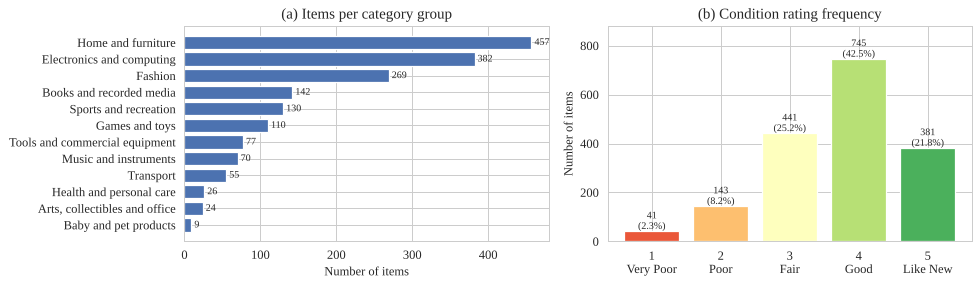

In [13]:
cat_counts = clean["category_group"].value_counts()
cond_counts = cond.value_counts().sort_index()
colors = sns.color_palette("RdYlGn", 5)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].barh(cat_counts.index[::-1], cat_counts.values[::-1], color="#4C72B0")
for i in range(len(cat_counts)):
    v = cat_counts.values[::-1][i]
    ax[0].text(v + 4, i, str(v), va="center", fontsize=8)
ax[0].set_xlabel("Number of items")
ax[0].set_title("(a) Items per category group")

ax[1].bar(range(1, 6), cond_counts.values, color=colors)
for i in range(5):
    v = cond_counts.values[i]
    ax[1].text(i + 1, v + 10, str(v) + "\n(" + str(round(v / len(clean) * 100, 1)) + "%)", ha="center", fontsize=8)
ax[1].set_xticks([1, 2, 3, 4, 5])
ax[1].set_xticklabels(["1\nVery Poor", "2\nPoor", "3\nFair", "4\nGood", "5\nLike New"])
ax[1].set_ylim(0, 880)
ax[1].set_ylabel("Number of items")
ax[1].set_title("(b) Condition rating frequency")
plt.tight_layout()
plt.savefig("figures/fig1_category_condition.png", dpi=200, bbox_inches="tight")
plt.show()

price_ils
0-50         555
51-100       246
101-250      265
251-500      191
501-1000     190
1001-5000    235
>5000         69
Name: count, dtype: int64
items 5 years or less: 72.5 %
items 40 years or more: 80


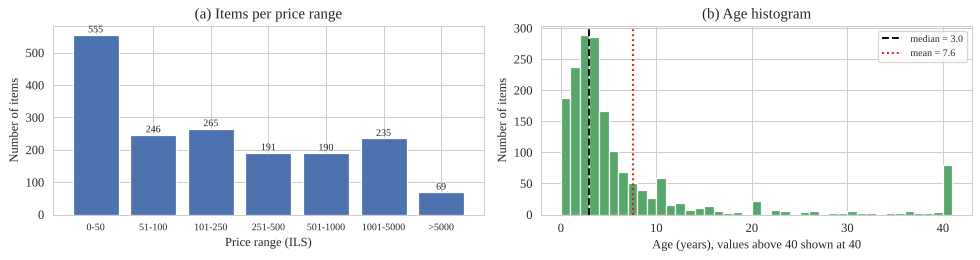

In [14]:
# price is from 0 to 800000 so a normal histogram is not readable,
# we use discretization (price ranges) like in the lecture
bins = [-0.1, 50, 100, 250, 500, 1000, 5000, 1e7]
labels = ["0-50", "51-100", "101-250", "251-500", "501-1000", "1001-5000", ">5000"]
price_range = pd.cut(price, bins=bins, labels=labels).value_counts().sort_index()
print(price_range)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.0))
ax[0].bar(price_range.index.astype(str), price_range.values, color="#4C72B0")
for i in range(len(price_range)):
    ax[0].text(i, price_range.values[i] + 8, str(price_range.values[i]), ha="center", fontsize=8)
ax[0].set_xlabel("Price range (ILS)")
ax[0].set_ylabel("Number of items")
ax[0].set_title("(a) Items per price range")
ax[0].tick_params(axis="x", labelsize=8)

ax[1].hist(age.clip(upper=40), bins=range(0, 42), color="#55A868", edgecolor="white")
ax[1].axvline(age.median(), color="black", ls="--", label="median = " + str(age.median()))
ax[1].axvline(age.mean(), color="red", ls=":", label="mean = " + str(round(age.mean(), 1)))
ax[1].set_xlabel("Age (years), values above 40 shown at 40")
ax[1].set_ylabel("Number of items")
ax[1].set_title("(b) Age histogram")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/fig2_price_age.png", dpi=200, bbox_inches="tight")
plt.show()

print("items 5 years or less:", round((age <= 5).mean() * 100, 1), "%")
print("items 40 years or more:", (age >= 40).sum())

* Home and furniture (457) and Electronics (382) are almost half of the data (48%). Baby/pet, art/office and health have less than 30 items each.
* Rating 4 (Good) is the most common (42.5%), and 4 + 5 together are 64%. People mostly sell items that are still good.
* Most items are cheap: 801 items (46%) cost 100 ILS or less, and only 69 items are above 5000 ILS (cars, instruments, antiques).
* Age is also right skewed: 72.5% of items are 5 years or less, but 80 items are 40 years or older.

### 4.3 Bivariate analysis
We use Pearson's r (from the lecture) and the scale: |r| < 0.4 no correlation, 0.4-0.6 some, 0.6-0.8 strong, > 0.8 very strong.
Pearson is affected by outliers, so we calculate it also after removing the IQR outliers.

In [15]:
def upper_fence(x):
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    return q3 + 1.5 * (q3 - q1)

print("price fence:", upper_fence(price), "| age fence:", upper_fence(age))
no_outliers = clean[(price <= upper_fence(price)) & (age <= upper_fence(age))]
only_original = clean[clean["original_values"]]

cols3 = ["condition_rating", "age_years", "price_ils"]
print("\nall rows, n =", len(clean))
print(clean[cols3].corr().round(2))
print("\nwithout IQR outliers, n =", len(no_outliers))
print(no_outliers[cols3].corr().round(2))
print("\noriginal values only, n =", len(only_original))
print(only_original[cols3].corr().round(2))

price fence: 1524.6999999999998 | age fence: 12.0

all rows, n = 1751
                  condition_rating  age_years  price_ils
condition_rating              1.00      -0.17       0.01
age_years                    -0.17       1.00       0.04
price_ils                     0.01       0.04       1.00

without IQR outliers, n = 1364
                  condition_rating  age_years  price_ils
condition_rating              1.00      -0.33       0.08
age_years                    -0.33       1.00       0.12
price_ils                     0.08       0.12       1.00

original values only, n = 1358
                  condition_rating  age_years  price_ils
condition_rating              1.00      -0.18       0.00
age_years                    -0.18       1.00       0.06
price_ils                     0.00       0.06       1.00


condition_rating
1     99.98
2     88.01
3    120.00
4    153.80
5    170.00
Name: price_ils, dtype: float64


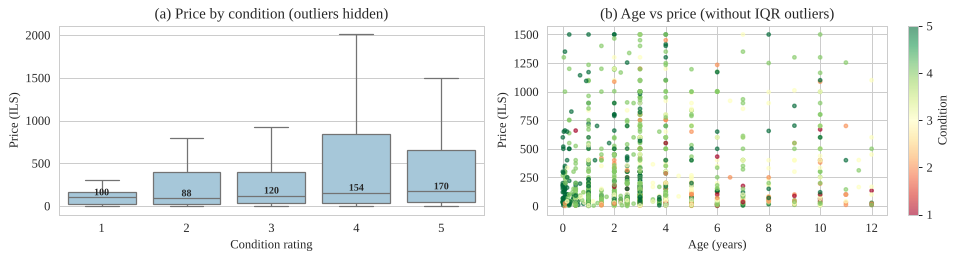

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.0))
sns.boxplot(data=clean, x="condition_rating", y="price_ils", showfliers=False, color="#9ecae1", ax=ax[0])
medians = clean.groupby("condition_rating")["price_ils"].median()
for i in range(5):
    ax[0].text(i, medians.values[i] + 25, str(round(medians.values[i])), ha="center", fontsize=8, fontweight="bold")
ax[0].set_xlabel("Condition rating")
ax[0].set_ylabel("Price (ILS)")
ax[0].set_title("(a) Price by condition (outliers hidden)")

sc = ax[1].scatter(no_outliers["age_years"], no_outliers["price_ils"], c=no_outliers["condition_rating"],
                   cmap="RdYlGn", s=8, alpha=0.6)
ax[1].set_xlabel("Age (years)")
ax[1].set_ylabel("Price (ILS)")
ax[1].set_title("(b) Age vs price (without IQR outliers)")
plt.colorbar(sc, ax=ax[1], label="Condition")
plt.tight_layout()
plt.savefig("figures/fig3_condition_age_price.png", dpi=200, bbox_inches="tight")
plt.show()
print(medians)

* **Condition and price:** the median goes up from about 100 ILS (rating 1) to 170 ILS (rating 5), but the boxes are almost on top of each other. Pearson r = 0.01 for all rows and 0.08 without outliers, so by the lecture scale there is **no correlation**.
* **Age and price:** r = 0.04 (0.12 without outliers), also no correlation. Older items are not cheaper, because the oldest items are antiques, cars and instruments that keep there value.
* **Age and condition:** this is the strongest one, r = −0.17 for all rows but −0.33 without outliers, older items are in worse condition. Still under 0.4, so its weak.
* The results with original values only are almost the same, so the imputation didnt change the results.

                                items  median_price  mean_price  mean_condition
category_group                                                                 
Arts, collectibles and office      24          15.0       132.0             3.6
Books and recorded media          142          25.0        75.6             3.6
Tools and commercial equipment     77          50.8     10613.1             3.5
Health and personal care           26          55.0      1180.5             3.7
Games and toys                    110          56.3       308.3             3.9
Fashion                           269          80.0       837.6             3.9
Baby and pet products               9         170.0       283.1             4.6
Home and furniture                457         180.0       621.8             3.7
Sports and recreation             130         300.0      1024.4             3.8
Electronics and computing         382         400.0       773.9             3.7
Music and instruments              70   

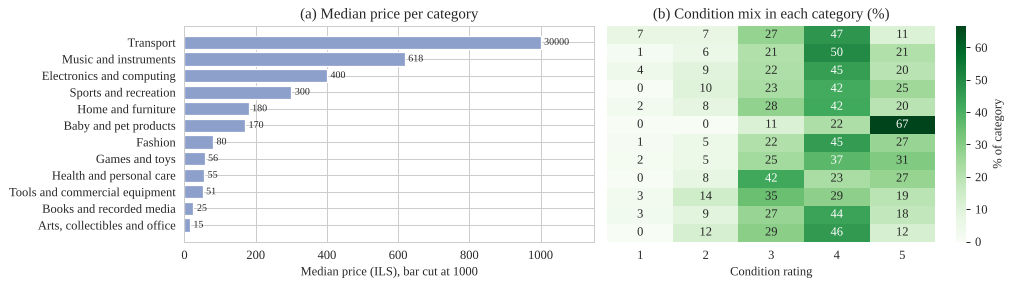

In [17]:
cat_stats = pd.DataFrame()
cat_stats["items"] = clean.groupby("category_group")["price_ils"].count()
cat_stats["median_price"] = clean.groupby("category_group")["price_ils"].median()
cat_stats["mean_price"] = clean.groupby("category_group")["price_ils"].mean()
cat_stats["mean_condition"] = clean.groupby("category_group")["condition_rating"].mean()
cat_stats = cat_stats.sort_values("median_price")
print(cat_stats.round(1))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.3))
ax[0].barh(cat_stats.index, cat_stats["median_price"].clip(upper=1000), color="#8DA0CB")   # transport is too big, we cut the bar
for i in range(len(cat_stats)):
    v = cat_stats["median_price"].values[i]
    ax[0].text(min(v, 1000) + 10, i, str(round(v)), va="center", fontsize=8)
ax[0].set_xlim(0, 1150)
ax[0].set_xlabel("Median price (ILS), bar cut at 1000")
ax[0].set_title("(a) Median price per category")

mix = pd.crosstab(clean["category_group"], clean["condition_rating"], normalize="index").loc[cat_stats.index[::-1]] * 100   # same order as the bars
sns.heatmap(mix, annot=True, fmt=".0f", cmap="Greens", cbar_kws={"label": "% of category"}, ax=ax[1])
ax[1].set_xlabel("Condition rating")
ax[1].set_ylabel("")
ax[1].set_yticklabels([])
ax[1].set_title("(b) Condition mix in each category (%)")
plt.tight_layout()
plt.savefig("figures/fig4_category.png", dpi=200, bbox_inches="tight")
plt.show()

* **Category and price:** this is the biggest difference in the data. The median is 15 ILS for art/office and 25 ILS for books, but 618 ILS for instruments and 30000 ILS for transport (the bar is cut).
* **Category and condition:** most categories have mostly 3 and 4. Baby/pet and fashion have more 5, tools and transport have more 3 or less.

### 4.4 Multivariate analysis
**Question 1: is the effect of condition on price the same in all categories?**
We compare the median price of good items (4-5) with fair or worse items (1-3) in each category (only categories with 50+ items).

                         category    n  median 1-3  median 4-5  ratio  pearson r
7                  Games and toys  110       87.51       50.18   0.57      -0.02
3           Music and instruments   70      893.56      575.00   0.64       0.14
4        Books and recorded media  142       25.00       25.00   1.00      -0.10
1              Home and furniture  457      150.00      200.00   1.33       0.10
5                         Fashion  269       60.00       80.00   1.33       0.13
0                       Transport   55    29000.00    40578.75   1.40       0.20
8           Sports and recreation  130      180.00      327.81   1.82       0.03
6  Tools and commercial equipment   77       41.49       98.40   2.37       0.09
2       Electronics and computing  382      180.00      550.00   3.06       0.18


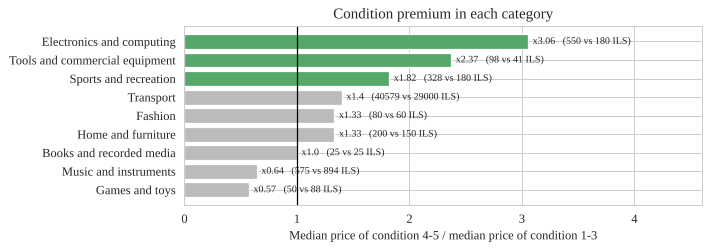

In [18]:
rows = []
for g in clean["category_group"].unique():
    d = clean[clean["category_group"] == g]
    if len(d) < 50:      # small categories are not reliable
        continue
    low = d[d["condition_rating"] <= 3]["price_ils"].median()
    high = d[d["condition_rating"] >= 4]["price_ils"].median()
    d2 = d[d["price_ils"] <= upper_fence(d["price_ils"])]     # remove outliers inside the category
    r = d2["condition_rating"].corr(d2["price_ils"])
    rows.append([g, len(d), low, high, high / low, r])

premium = pd.DataFrame(rows, columns=["category", "n", "median 1-3", "median 4-5", "ratio", "pearson r"])
premium = premium.sort_values("ratio")
print(premium.round(2))

fig, ax = plt.subplots(figsize=(8, 2.9))
bar_colors = []
for v in premium["ratio"]:
    if v > 1.5:
        bar_colors.append("#55A868")    # green = clear premium
    else:
        bar_colors.append("#BBBBBB")
ax.barh(premium["category"], premium["ratio"], color=bar_colors)
ax.axvline(1, color="black", lw=1)
for i in range(len(premium)):
    row = premium.iloc[i]
    text = "x" + str(round(row["ratio"], 2)) + "   (" + str(round(row["median 4-5"])) + " vs " + str(round(row["median 1-3"])) + " ILS)"
    ax.text(row["ratio"] + 0.04, i, text, va="center", fontsize=8)
ax.set_xlim(0, 4.6)
ax.set_xlabel("Median price of condition 4-5 / median price of condition 1-3")
ax.set_title("Condition premium in each category")
plt.tight_layout()
plt.savefig("figures/fig5_condition_premium.png", dpi=200, bbox_inches="tight")
plt.show()

The answer is no, its different. In electronics the good items are 3 times more expensive (550 vs 180 ILS), and in tools 2.4 times. But in books the median is the same, and for games and instruments the good items are even cheaper, because there the price depends on the title or the brand, not on the condition.
The Pearson r inside each category is under 0.25 in all of them, so the medians show the difference better than r.

**Question 2: are old items in good condition priced different from old items in bad condition?**
Here we use discretization again: age bands.

In [19]:
clean["age_band"] = pd.cut(age, bins=[-0.1, 1, 3, 7, 15, 1000], labels=["≤1", "1-3", "3-7", "7-15", ">15"])
clean["condition_group"] = np.where(cond >= 4, "Good / Like new (4-5)", "Fair or worse (1-3)")

print(clean.groupby(["age_band", "condition_group"])["price_ils"].median().unstack().round(0))
print("\nmean condition per age band:")
print(clean.groupby("age_band")["condition_rating"].mean().round(2))

old = clean[clean["age_years"] > 7]
young = clean[clean["age_years"] <= 3]
old_good = old[old["condition_rating"] >= 4]["price_ils"].median()
old_bad = old[old["condition_rating"] <= 3]["price_ils"].median()
young_good = young[young["condition_rating"] >= 4]["price_ils"].median()
young_bad = young[young["condition_rating"] <= 3]["price_ils"].median()
print("\nolder than 7 years: good =", round(old_good), " bad =", round(old_bad), " ratio =", round(old_good / old_bad, 1))
print("3 years or less: good =", round(young_good), " bad =", round(young_bad), " ratio =", round(young_good / young_bad, 1))

old_o = old[old["original_values"]]
print("older than 7, original values only: good =", old_o[old_o["condition_rating"] >= 4]["price_ils"].median(),
      " bad =", old_o[old_o["condition_rating"] <= 3]["price_ils"].median())

condition_group  Fair or worse (1-3)  Good / Like new (4-5)
age_band                                                   
≤1                              55.0                   84.0
1-3                             88.0                  187.0
3-7                             80.0                  200.0
7-15                           149.0                  656.0
>15                            170.0                  345.0

mean condition per age band:
age_band
≤1      4.28
1-3     3.83
3-7     3.54
7-15    3.24
>15     3.20
Name: condition_rating, dtype: float64

older than 7 years: good = 484  bad = 167  ratio = 2.9
3 years or less: good = 130  bad = 80  ratio = 1.6
older than 7, original values only: good = 400.0  bad = 166.11


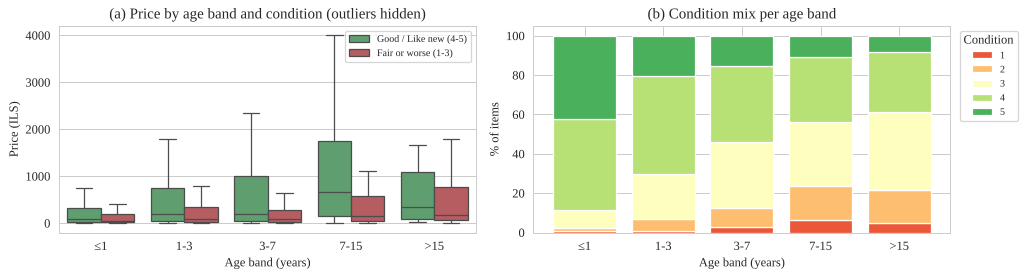

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.2))
sns.boxplot(data=clean, x="age_band", y="price_ils", hue="condition_group", showfliers=False, ax=ax[0],
            palette={"Good / Like new (4-5)": "#55A868", "Fair or worse (1-3)": "#C44E52"})
ax[0].set_xlabel("Age band (years)")
ax[0].set_ylabel("Price (ILS)")
ax[0].set_title("(a) Price by age band and condition (outliers hidden)")
ax[0].legend(fontsize=8)

mix_age = pd.crosstab(clean["age_band"], clean["condition_rating"], normalize="index") * 100
mix_age.plot(kind="bar", stacked=True, color=colors, ax=ax[1], width=0.8)
ax[1].set_xlabel("Age band (years)")
ax[1].set_ylabel("% of items")
ax[1].tick_params(axis="x", rotation=0)
ax[1].set_title("(b) Condition mix per age band")
ax[1].legend(title="Condition", fontsize=8, bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig("figures/fig6_age_condition_price.png", dpi=200, bbox_inches="tight")
plt.show()

Yes. For items older than 7 years, the good ones have median 484 ILS and the bad ones 167 ILS, almost **3 times** more. For new items (3 years or less) its only 1.6 times.
With original values only it is 400 vs 166, so the same result. Also the mean condition goes down from 4.28 (≤1 year) to 3.20 (>15 years).

In [21]:
# the most expensive and the oldest items (we kept them)
show = ["title_clean", "category_group", "age_years", "condition_rating", "price_ils"]
print(clean.nlargest(6, "price_ils")[show])
print()
print(clean.nlargest(5, "age_years")[show])
print("\nforeign currency rows:", round((clean["currency_original_code"] != "ILS").sum() / len(clean) * 100, 1), "%")

                                            title_clean                  category_group  age_years  condition_rating  price_ils
1329                                       chicken farm  Tools and commercial equipment        3.0                 4  800000.00
1280  Vintage 1954 Fender Stratocaster Sunburst Soli...           Music and instruments       72.0                 3  451575.00
295                              2022 BMW 5 Series 545e                       Transport        4.0                 4  350000.00
2                                   Lexus LX 600 Luxury                       Transport        3.0                 5  302558.60
296                          Mercedes-Benz GLS 400 2018                       Transport        8.0                 3  270000.00
1                        Mercedes-Benz AMG GT 63 4MATIC                       Transport        7.0                 4  265633.14

                                            title_clean      category_group  age_years  condition_ratin

## 5. Insights

1. **The average price is misleading.** Mean 3347 ILS but median 140 ILS, and the top 1% of items have 66% of all the money. So a marketplace should show the median or price ranges for each category.
2. **What the item is, is more important than its condition.** Medians go from 15 ILS to 30000 ILS between categories, but only from 100 to 170 ILS between condition 1 and 5. For a price model the category is the most important feature.
3. **Condition matters only in some categories.** Electronics x3.06, tools x2.37, sports x1.82, but books x1.0 and games/instruments below 1.
4. **Age makes the condition worse, not the price lower.** Age and condition r = −0.33 (without outliers) but age and price no correlation. "Older = cheaper" is not true in a mixed market.
5. **For old items, condition is the price signal.** Old items in good condition are about 3 times more expensive than old items in bad condition (1.6 times for new items).
6. **The data is what students collected, not the whole market.** Home and electronics are about half, some groups have less than 30 items and 33% of prices was in foreign currency (mostly USD online ads).

## 6. Limitations
* 21% of ages was missing, 311 were filled with the median, this pull the values to the middle.
* Some categories are very small, so there results are not stable.
* Condition is subjective, each student rated alone.
* Ages are guesses in many rows.
* Prices are asking prices (not sold), from 16 currencies with one exchange rate.

**For the future:** one template for all students (fixed columns, category list, price + currency columns, age in years), add price type and source, example photos for each condition grade, and check new items against old ones to avoid duplicates.